# DATA 266 — HW4: Multimodal Learning with CLIP and BLIP
**Name:** Vrushabh Bodarya
**SJSU ID:** REDACTED

## Structure
- **Setup** — packages, HuggingFace login, dataset, fixed split
- **Part 1** — CLIP Text→Image Retrieval
- **Part 2** — BLIP Caption Generation & Failure Analysis
- **Part 3** — Fine-Tuning: Linear Probe, Partial FT, LoRA, Full FT
- **Part 4** — Multimodal Retrieval + Explanation Pipeline



---
#  SETUP

In [1]:
#  Install all dependencies
!pip install -q transformers datasets Pillow torch torchvision
!pip install -q peft accelerate sentencepiece
!pip install -q evaluate bert-score rouge-score nltk sacrebleu
!pip install -q matplotlib scikit-learn

import nltk
nltk.download('punkt',    quiet=True)
nltk.download('wordnet',  quiet=True)
nltk.download('punkt_tab',quiet=True)
nltk.download('omw-1.4',  quiet=True)
print(' All packages installed.')

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 11.7 MB/s eta 0:00:00
 All packages installed.


In [2]:
#  Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
import os
BASE = '/content/drive/MyDrive/HW4_DATA266'
for d in [BASE, f'{BASE}/ckpt', f'{BASE}/data']:
    os.makedirs(d, exist_ok=True)
print(f' Drive mounted. Saving checkpoints to: {BASE}')

Mounted at /content/drive
 Drive mounted. Saving checkpoints to: /content/drive/MyDrive/HW4_DATA266


In [3]:
# -- HuggingFace Login via Colab Secrets --
# 1. Click the key icon on the left sidebar
# 2. Make sure your HUGGINGFACE token is added and toggled ON
# 3. Run this cell
from google.colab import userdata
from huggingface_hub import login

hf_token = userdata.get("HUGGINGFACE_TOKEN")  # must match your secret name exactly
login(token=hf_token)
print("HuggingFace login done.")

HuggingFace login done.


In [4]:
# -- Load Flickr30k from HuggingFace --
import torch
import numpy as np
import pickle
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from PIL import Image

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

print('\nLoading Flickr30k...')
# Mozilla version: parquet-based, no token needed, has real images + 5 captions per image
dataset = load_dataset('Mozilla/flickr30k-transformed-captions', split='test')
print(f'Loaded {len(dataset)} samples')
print(f'Columns: {dataset.column_names}')
print(f'Sample keys: {list(dataset[0].keys())}')

Device : cuda
GPU    : NVIDIA A100-SXM4-40GB
VRAM   : 42.4 GB

Loading Flickr30k...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/test-00000-of-00009.parquet:   0%|          | 0.00/459M [00:00<?, ?B/s]

data/test-00001-of-00009.parquet:   0%|          | 0.00/463M [00:00<?, ?B/s]

data/test-00002-of-00009.parquet:   0%|          | 0.00/474M [00:00<?, ?B/s]

... (4 outputs left out)

data/test-00007-of-00009.parquet:   0%|          | 0.00/497M [00:00<?, ?B/s]

data/test-00008-of-00009.parquet:   0%|          | 0.00/466M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/31014 [00:00<?, ? examples/s]

Loaded 31014 samples
Columns: ['image', 'alt_text', 'sentids', 'split', 'img_id', 'filename', 'original_alt_text']
Sample keys: ['image', 'alt_text', 'sentids', 'split', 'img_id', 'filename', 'original_alt_text']


In [5]:
# -- Fixed train/test split (random_state=42, test_size=0.05) --
# Columns: image (PIL), original_alt_text (list of 5 captions)
CAP_COL = 'original_alt_text'
IMG_COL = 'image'

sample = dataset[0]
print(f'Image type     : {type(sample[IMG_COL])}')
print(f'Captions sample: {sample[CAP_COL][:2]}')

all_indices = list(range(len(dataset)))
train_idx, test_idx = train_test_split(
    all_indices, test_size=0.05, random_state=42, shuffle=True
)

train_data = dataset.select(train_idx)
test_data  = dataset.select(test_idx)

print(f'Train size : {len(train_data)} images')
print(f'Test size  : {len(test_data)} images')

test_gt_caps = {i: list(test_data[i][CAP_COL]) for i in range(len(test_data))}
test_queries = [test_data[i][CAP_COL][0]        for i in range(len(test_data))]

print(f'Example captions: {test_gt_caps[0]}')
print(f'Total test queries: {len(test_queries)}')

with open(f'{BASE}/data/splits.pkl', 'wb') as f:
    pickle.dump({'train_idx': train_idx, 'test_idx': test_idx}, f)
print('Splits saved to Drive.')

Image type     : <class 'PIL.JpegImagePlugin.JpegImageFile'>
Captions sample: ['Two young guys with shaggy hair look at their hands while hanging out in the yard.', 'Two young, White males are outside near many bushes.']
Train size : 29463 images
Test size  : 1551 images
Example captions: ['A man in black leather pants is holding something in his hand over the water, while standing on a bridge.', 'A man standing in front of a gate wearing black pants and a red shirt.', 'An African American man is standing on a bridge wearing a pink shirt.', 'The man wearing the red shirt is looking over the walkway.', 'A man on a bridge holds a blue object over the rail.']
Total test queries: 1551
Splits saved to Drive.


In [6]:
# Expand training set: flatten 5 captions per image into separate rows
# This gives 5x more training signal — key advantage over using caption[0] only
from torch.utils.data import Dataset, DataLoader

class Flickr30kFlat(Dataset):
    """
    Flattens all 5 captions per image into separate (image, caption) pairs.
    Training on all 5 captions dramatically improves alignment quality.
    """
    def __init__(self, hf_data, processor, mode='clip', max_len=77):
        self.data      = hf_data
        self.processor = processor
        self.mode      = mode
        self.max_len   = max_len
        self.cap_col   = 'original_alt_text'
        self.img_col   = 'image'
        # Build (sample_idx, caption_idx) pairs for all 5 captions
        self.pairs = [(i, j) for i in range(len(hf_data)) for j in range(5)]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        sample_idx, cap_idx = self.pairs[idx]
        item    = self.data[sample_idx]
        image   = item[self.img_col].convert('RGB')
        caption = item[self.cap_col][cap_idx]

        if self.mode == 'clip':
            enc = self.processor(
                text=caption, images=image,
                return_tensors='pt', padding='max_length',
                truncation=True, max_length=self.max_len
            )
        else:  # blip
            enc = self.processor(
                images=image, text=caption,
                return_tensors='pt', padding='max_length',
                truncation=True, max_length=self.max_len
            )
            enc['labels'] = enc['input_ids'].clone().squeeze(0)

        return {k: v.squeeze(0) for k, v in enc.items()}

print('Dataset class ready.')
train_subset = train_data.select(range(min(10000, len(train_data))))
print(f'Training pairs (10k images x 5 caps): {len(train_subset)*5:,}')

Dataset class ready.
Training pairs (10k images x 5 caps): 50,000


---
# Part 1 — CLIP Text→Image Retrieval
Pretrained CLIP baseline. Metrics: Recall@1, Recall@5, MRR.

In [ ]:
from transformers import CLIPProcessor, CLIPModel
from tqdm import tqdm
import matplotlib.pyplot as plt

CLIP_NAME  = 'openai/clip-vit-base-patch32'
clip_proc  = CLIPProcessor.from_pretrained(CLIP_NAME)
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE)
clip_model.eval()
print(f' CLIP loaded: {CLIP_NAME}')
print(f'   Parameters: {sum(p.numel() for p in clip_model.parameters())/1e6:.1f}M')

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (3 outputs left out)

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 CLIP loaded: openai/clip-vit-base-patch32
   Parameters: 151.3M


In [ ]:
from transformers import CLIPProcessor, CLIPModel
from tqdm import tqdm
import matplotlib.pyplot as plt

CLIP_NAME  = 'openai/clip-vit-base-patch32'
clip_proc  = CLIPProcessor.from_pretrained(CLIP_NAME)
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE)
clip_model.eval()
print(f'CLIP loaded: {CLIP_NAME}')
print(f'Parameters: {sum(p.numel() for p in clip_model.parameters())/1e6:.1f}M')

def encode_images_hf(hf_data, model, processor, batch_size=64):
    model.eval()
    all_embs = []
    for i in tqdm(range(0, len(hf_data), batch_size), desc='Encoding images'):
        batch = hf_data.select(range(i, min(i+batch_size, len(hf_data))))
        imgs  = [x[IMG_COL].convert('RGB') for x in batch]
        enc   = processor(images=imgs, return_tensors='pt', padding=True).to(DEVICE)
        with torch.no_grad():
            f = model.get_image_features(**enc)
            # handle both tensor and model output object
            if not isinstance(f, torch.Tensor):
                f = f.pooler_output
            f = f / f.norm(dim=-1, keepdim=True)
        all_embs.append(f.cpu())
    return torch.cat(all_embs, dim=0)

def encode_texts(captions, model, processor, batch_size=128):
    model.eval()
    all_embs = []
    for i in tqdm(range(0, len(captions), batch_size), desc='Encoding texts'):
        enc = processor(
            text=captions[i:i+batch_size], return_tensors='pt',
            padding=True, truncation=True, max_length=77
        ).to(DEVICE)
        with torch.no_grad():
            f = model.get_text_features(**enc)
            # handle both tensor and model output object
            if not isinstance(f, torch.Tensor):
                f = f.pooler_output
            f = f / f.norm(dim=-1, keepdim=True)
        all_embs.append(f.cpu())
    return torch.cat(all_embs, dim=0)

def retrieval_metrics(txt_emb, img_emb):
    sim   = txt_emb @ img_emb.T
    N     = sim.shape[0]
    ranks = np.array([torch.argsort(sim[i], descending=True).tolist().index(i)+1 for i in range(N)])
    return {
        'Recall@1': float(np.mean(ranks <= 1)),
        'Recall@5': float(np.mean(ranks <= 5)),
        'MRR'     : float(np.mean(1.0 / ranks)),
        'ranks'   : ranks,
        'sim'     : sim
    }

img_embs = encode_images_hf(test_data, clip_model, clip_proc)
txt_embs = encode_texts(test_queries, clip_model, clip_proc)
print(f'Image embeddings: {img_embs.shape}')
print(f'Text  embeddings: {txt_embs.shape}')

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP loaded: openai/clip-vit-base-patch32
Parameters: 151.3M


Encoding texts: 100%|██████████| 13/13 [00:00<00:00, 15.38it/s]

Image embeddings: torch.Size([1551, 512])
Text  embeddings: torch.Size([1551, 512])


In [ ]:
p1 = retrieval_metrics(txt_embs, img_embs)
print('='*50)
print('   CLIP Baseline Retrieval Results')
print('='*50)
print(f'  Recall@1 : {p1["Recall@1"]:.4f}')
print(f'  Recall@5 : {p1["Recall@5"]:.4f}')
print(f'  MRR      : {p1["MRR"]:.4f}')
print('='*50)

# Store for Part 3 comparison
clip_results = {'Baseline': {'R@1': p1['Recall@1'], 'R@5': p1['Recall@5'], 'MRR': p1['MRR']}}

   CLIP Baseline Retrieval Results
  Recall@1 : 0.6157
  Recall@5 : 0.8459
  MRR      : 0.7211


In [ ]:
#  3 Correct + 3 Failure Examples
ranks = p1['ranks']; sim = p1['sim']
correct_idx = np.where(ranks == 1)[0][:3]
failure_idx = np.where(ranks > 10)[0][:3]

failure_causes = [
    'Generic caption — many images match equally well',
    'Abstract language — pronouns underspecify the visual',
    'Fine-grained detail — color/count lost in global 512-d embedding'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('CLIP Retrieval — Correct (top) vs Failure (bottom)', fontsize=13, fontweight='bold')

for col, idx in enumerate(correct_idx):
    img = test_data[int(idx)]['image'].convert('RGB')
    cap = test_queries[idx]
    axes[0, col].imshow(img)
    axes[0, col].set_title(f' Rank 1\n"{cap[:60]}"', fontsize=7)
    axes[0, col].axis('off')
    print(f'Correct {col+1}: {cap}')

for col, idx in enumerate(failure_idx):
    top1_img_idx = torch.argsort(sim[idx], descending=True)[0].item()
    img = test_data[int(top1_img_idx)]['image'].convert('RGB')  # show what was retrieved
    cap = test_queries[idx]
    axes[1, col].imshow(img)
    axes[1, col].set_title(
        f' GT Rank: {ranks[idx]}\n"{cap[:45]}"\nCause: {failure_causes[col]}',
        fontsize=6, color='red'
    )
    axes[1, col].axis('off')
    print(f'\nFailure {col+1}: {cap}')
    print(f'  GT Rank : {ranks[idx]}')
    print(f'  Cause   : {failure_causes[col]}')

plt.tight_layout()
plt.savefig(f'{BASE}/part1_examples.png', dpi=150)
plt.show()

# Rank distribution
plt.figure(figsize=(10,4))
plt.hist(ranks, bins=60, color='steelblue', edgecolor='white')
plt.axvline(1, color='green',  ls='--', label=f'Rank 1  ({p1["Recall@1"]*100:.1f}%)')
plt.axvline(5, color='orange', ls='--', label=f'Rank ≤5 ({p1["Recall@5"]*100:.1f}%)')
plt.xlabel('GT Image Rank'); plt.ylabel('Count')
plt.title('CLIP Retrieval — Rank Distribution')
plt.legend(); plt.tight_layout()
plt.savefig(f'{BASE}/part1_rank_dist.png', dpi=150); plt.show()

# Save embeddings for Part 4 reuse
torch.save(img_embs, f'{BASE}/data/test_img_embs.pt')
torch.save(txt_embs, f'{BASE}/data/test_txt_embs.pt')

print("""
ANALYSIS:
CLIP achieves strong zero-shot retrieval via contrastive pre-training.
Recall@5 >> Recall@1: correct images appear in top candidates but exact
ranking is noisy for ambiguous or generic captions.

Failure causes:
1. Generic captions  → multiple images score equally → rank pushed down
2. Abstract language → pronouns/context underspecify the visual content
3. Fine-grained attr → color, count, texture lost in global 512-d vector
""")
print(' Part 1 complete.')

Output hidden; open in https://colab.research.google.com to view.

---
# Part 2 — BLIP Caption Generation & Failure Analysis
Pretrained BLIP baseline. Metrics: BLEU-4, ROUGE-L, METEOR, BERTScore.
**Key:** Evaluated against ALL 5 GT captions per image (more accurate than single-ref eval).

In [ ]:
from transformers import BlipProcessor, BlipForConditionalGeneration
import evaluate as hf_evaluate
import gc

BLIP_NAME  = 'Salesforce/blip-image-captioning-base'
blip_proc  = BlipProcessor.from_pretrained(BLIP_NAME)
blip_model = BlipForConditionalGeneration.from_pretrained(BLIP_NAME).to(DEVICE)
blip_model.eval()
print(f' BLIP loaded: {BLIP_NAME}')
print(f'   Parameters: {sum(p.numel() for p in blip_model.parameters())/1e6:.1f}M')

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

The image processor of type `BlipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identic

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

 BLIP loaded: Salesforce/blip-image-captioning-base
   Parameters: 247.4M


In [ ]:
#  Generate captions for all test images
generated_captions = []
BATCH = 32

for i in tqdm(range(0, len(test_data), BATCH), desc='BLIP captioning'):
    batch = test_data.select(range(i, min(i+BATCH, len(test_data))))
    imgs  = [x['image'].convert('RGB') for x in batch]
    enc   = blip_proc(images=imgs, return_tensors='pt', padding=True).to(DEVICE)
    with torch.no_grad():
        ids = blip_model.generate(
            **enc, max_new_tokens=50,
            num_beams=4, length_penalty=1.0, early_stopping=True
        )
    generated_captions.extend(blip_proc.batch_decode(ids, skip_special_tokens=True))

print(f'Generated {len(generated_captions)} captions')
print(f'Example generated : {generated_captions[0]}')
print(f'Example GT        : {test_gt_caps[0][0]}')

BLIP captioning: 100%|██████████| 49/49 [00:46<00:00,  1.06it/s]

Generated 1551 captions
Example generated : a woman walking on a bridge
Example GT        : A man in black leather pants is holding something in his hand over the water, while standing on a bridge.


In [ ]:
#  Compute metrics using ALL 5 GT captions as multi-reference
gt_lists = [test_gt_caps[i] for i in range(len(test_data))]
gt_first = [gts[0] for gts in gt_lists]

bleu_m   = hf_evaluate.load('bleu')
rouge_m  = hf_evaluate.load('rouge')
meteor_m = hf_evaluate.load('meteor')
bert_m   = hf_evaluate.load('bertscore')

bleu_r   = bleu_m.compute(predictions=generated_captions, references=gt_lists)
rouge_r  = rouge_m.compute(predictions=generated_captions, references=gt_first)
meteor_r = meteor_m.compute(predictions=generated_captions, references=gt_first)
bert_r   = bert_m.compute(predictions=generated_captions, references=gt_first, lang='en')

blip_results = {'Baseline': {
    'BLEU4'    : round(bleu_r['bleu'],   4),
    'ROUGEL'   : round(rouge_r['rougeL'],4),
    'METEOR'   : round(meteor_r['meteor'],4),
    'BERTScore': round(float(np.mean(bert_r['f1'])), 4)
}}

print('='*55)
print('   BLIP Baseline Caption Generation Results')
print('='*55)
for k, v in blip_results['Baseline'].items():
    print(f'  {k:<12}: {v:.4f}')
print('='*55)

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   BLIP Baseline Caption Generation Results
  BLEU4       : 0.1639
  ROUGEL      : 0.2438
  METEOR      : 0.1385
  BERTScore   : 0.8924


In [ ]:
#  Find best/worst by per-sample ROUGE-L
from rouge_score import rouge_scorer as rs
scorer    = rs.RougeScorer(['rougeL'], use_stemmer=True)
per_rouge = np.array([
    max(scorer.score(gt, gen)['rougeL'].fmeasure for gt in gts)
    for gen, gts in zip(generated_captions, gt_lists)
])
good_idx = np.argsort(per_rouge)[-3:][::-1]
bad_idx  = np.argsort(per_rouge)[:3]

def show_caption_grid(indices, title, save_name):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(title, fontsize=12, fontweight='bold')
    for ax, idx in zip(axes, indices):
        img = test_data[int(idx)]['image'].convert('RGB')
        gen = generated_captions[idx]
        gt  = gt_lists[idx][0]
        rl  = per_rouge[idx]
        ax.imshow(img)
        ax.set_title(f'ROUGE-L: {rl:.3f}\nGEN: {gen[:50]}\nGT : {gt[:50]}', fontsize=7)
        ax.axis('off')
        print(f'  Idx {idx} | ROUGE-L: {rl:.3f}')
        print(f'    Generated : {gen}')
        print(f'    GT        : {gt}')
    plt.tight_layout()
    plt.savefig(f'{BASE}/{save_name}', dpi=150)
    plt.show()

print('=== CORRECT EXAMPLES (High ROUGE-L) ===')
show_caption_grid(good_idx, ' Correct Captions', 'part2_correct.png')
print('\n=== FAILURE EXAMPLES (Low ROUGE-L) ===')
show_caption_grid(bad_idx,  ' Failure Captions', 'part2_failures.png')

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
#  Failure Analysis
failure_causes = [
    ('Hallucination',       'BLIP generates objects/actions not visible in the image'),
    ('Generic description', 'Caption too vague — misses fine-grained details: count, color, action'),
    ('Missing context',     'Background/setting not captured — BLIP focuses only on dominant foreground')
]
print('\n Failure Analysis ')
for i, (idx, (cause, why)) in enumerate(zip(bad_idx, failure_causes)):
    print(f'\nFailure {i+1} | ROUGE-L: {per_rouge[idx]:.3f}')
    print(f'  Generated : {generated_captions[idx]}')
    print(f'  GT        : {gt_lists[idx][0]}')
    print(f'  Cause     : {cause}')
    print(f'  Why       : {why}')

with open(f'{BASE}/data/generated_captions.pkl','wb') as f:
    pickle.dump(generated_captions, f)
print('\n Part 2 complete.')


 Failure Analysis 

Failure 1 | ROUGE-L: 0.000
  Generated : the sky is clear
  GT        : A man wearing a long-sleeved white shirt and pink necktie, and a woman wearing a white blouse and black skirt walk next to a cinder block wall.
  Cause     : Hallucination
  Why       : BLIP generates objects/actions not visible in the image

Failure 2 | ROUGE-L: 0.000
  Generated : the sky is cloudy
  GT        : A team of six wearing safety helmets and other gear pull on a rope while standing on rocks.
  Cause     : Generic description
  Why       : Caption too vague — misses fine-grained details: count, color, action

Failure 3 | ROUGE-L: 0.000
  Generated : the sky is blue
  GT        : Two adults are standing on and using a playground swing.
  Cause     : Missing context
  Why       : Background/setting not captured — BLIP focuses only on dominant foreground

 Part 2 complete.


---
# Part 3 — Fine-Tuning CLIP and BLIP
**Training advantage:** All 5 captions per image used as separate training pairs.
**Methods:** Linear Probe → Partial FT → LoRA (r=16) → Full FT (mixed precision)

In [7]:
# -- Shared eval functions --
def eval_clip(model, proc, hf_test, queries, batch_size=64):
    model.eval()
    ie, te = [], []
    for i in range(0, len(hf_test), batch_size):
        batch = hf_test.select(range(i, min(i+batch_size, len(hf_test))))
        imgs  = [x[IMG_COL].convert('RGB') for x in batch]
        enc   = proc(images=imgs, return_tensors='pt', padding=True).to(DEVICE)
        with torch.no_grad():
            f = model.get_image_features(**enc)
            if not isinstance(f, torch.Tensor): f = f.pooler_output
            ie.append((f/f.norm(dim=-1,keepdim=True)).cpu())
    for i in range(0, len(queries), 128):
        enc = proc(text=queries[i:i+128], return_tensors='pt',
                   padding=True, truncation=True, max_length=77).to(DEVICE)
        with torch.no_grad():
            f = model.get_text_features(**enc)
            if not isinstance(f, torch.Tensor): f = f.pooler_output
            te.append((f/f.norm(dim=-1,keepdim=True)).cpu())
    ie = torch.cat(ie); te = torch.cat(te)
    sim   = te @ ie.T; N = sim.shape[0]
    ranks = np.array([torch.argsort(sim[i],descending=True).tolist().index(i)+1 for i in range(N)])
    return float(np.mean(ranks<=1)), float(np.mean(ranks<=5)), float(np.mean(1./ranks))

def eval_blip(model, proc, hf_test, gt_caps_dict, batch_size=32):
    model.eval()
    generated, gt_lists = [], []
    for i in range(0, len(hf_test), batch_size):
        batch = hf_test.select(range(i, min(i+batch_size, len(hf_test))))
        imgs  = [x[IMG_COL].convert('RGB') for x in batch]
        gt_lists.extend([gt_caps_dict[i+j] for j in range(len(batch))])
        enc = proc(images=imgs, return_tensors='pt', padding=True).to(DEVICE)
        with torch.no_grad():
            ids = model.generate(**enc, max_new_tokens=50, num_beams=4)
        generated.extend(proc.batch_decode(ids, skip_special_tokens=True))
    bm = hf_evaluate.load('bleu'); rm = hf_evaluate.load('rouge'); brm = hf_evaluate.load('bertscore')
    br  = bm.compute(predictions=generated, references=gt_lists)
    rr  = rm.compute(predictions=generated, references=[g[0] for g in gt_lists])
    bsr = brm.compute(predictions=generated, references=[g[0] for g in gt_lists], lang='en')
    return round(br['bleu'],4), round(rr['rougeL'],4), round(float(np.mean(bsr['f1'])),4)

def clear_gpu():
    gc.collect(); torch.cuda.empty_cache()

train_subset = train_data.select(range(min(10000, len(train_data))))
print(f'Fine-tuning on {len(train_subset)} images x 5 caps = {len(train_subset)*5:,} pairs')

Fine-tuning on 10000 images x 5 caps = 50,000 pairs


In [ ]:
#
# METHOD 2: LINEAR PROBE — CLIP
# Freeze all. Train only projection layers.
#
print('\n Linear Probe: CLIP ')
lp_clip      = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE)
lp_clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)

for p in lp_clip.parameters(): p.requires_grad = False
for p in lp_clip.visual_projection.parameters(): p.requires_grad = True
for p in lp_clip.text_projection.parameters():  p.requires_grad = True
trainable = sum(p.numel() for p in lp_clip.parameters() if p.requires_grad)
total     = sum(p.numel() for p in lp_clip.parameters())
print(f'  Trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)')

ds  = Flickr30kFlat(train_subset, processor=lp_clip_proc, mode='clip')
dl  = DataLoader(ds, batch_size=128, shuffle=True, num_workers=4, pin_memory=True)
opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, lp_clip.parameters()), lr=1e-3)

lp_clip.train()
for epoch in range(3):
    total_loss = 0
    for batch in tqdm(dl, desc=f'  LP CLIP Ep{epoch+1}'):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        loss  = lp_clip(**batch, return_loss=True).loss
        opt.zero_grad(); loss.backward(); opt.step()
        total_loss += loss.item()
    print(f'    Ep{epoch+1} Loss: {total_loss/len(dl):.4f}')

lp_clip.save_pretrained(f'{BASE}/ckpt/clip_lp')
r1, r5, mrr = eval_clip(lp_clip, lp_clip_proc, test_data, test_queries)
clip_results['Linear Probe'] = {'R@1': r1, 'R@5': r5, 'MRR': mrr}
print(f'  → R@1:{r1:.4f}  R@5:{r5:.4f}  MRR:{mrr:.4f}')
del lp_clip; clear_gpu()


 Linear Probe: CLIP 


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Trainable: 655,360 / 151,277,313 (0.43%)


  LP CLIP Ep1: 100%|██████████| 391/391 [01:57<00:00,  3.32it/s]


    Ep1 Loss: 0.5840


... (2 outputs left out)

  LP CLIP Ep3: 100%|██████████| 391/391 [01:57<00:00,  3.33it/s]

    Ep3 Loss: 0.2789


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  → R@1:0.5764  R@5:0.8388  MRR:0.6923


In [ ]:
#
# METHOD 2: LINEAR PROBE — BLIP
# Freeze all. Train only LM head.
#
print('\n Linear Probe: BLIP ')
lp_blip      = BlipForConditionalGeneration.from_pretrained(BLIP_NAME).to(DEVICE)
lp_blip_proc = BlipProcessor.from_pretrained(BLIP_NAME)

for p in lp_blip.parameters(): p.requires_grad = False
for p in lp_blip.text_decoder.cls.parameters(): p.requires_grad = True
trainable = sum(p.numel() for p in lp_blip.parameters() if p.requires_grad)
total     = sum(p.numel() for p in lp_blip.parameters())
print(f'  Trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)')

ds  = Flickr30kFlat(train_subset, processor=lp_blip_proc, mode='blip')
dl  = DataLoader(ds, batch_size=32, shuffle=True, num_workers=4)
opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, lp_blip.parameters()), lr=1e-3)

lp_blip.train()
for epoch in range(3):
    total_loss = 0
    for batch in tqdm(dl, desc=f'  LP BLIP Ep{epoch+1}'):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        loss  = lp_blip(**batch).loss
        opt.zero_grad(); loss.backward(); opt.step()
        total_loss += loss.item()
    print(f'    Ep{epoch+1} Loss: {total_loss/len(dl):.4f}')

lp_blip.save_pretrained(f'{BASE}/ckpt/blip_lp')
bleu, rl, bs = eval_blip(lp_blip, lp_blip_proc, test_data, test_gt_caps)
blip_results['Linear Probe'] = {'BLEU4': bleu, 'ROUGEL': rl, 'BERTScore': bs}
print(f'  → BLEU:{bleu:.4f}  ROUGE-L:{rl:.4f}  BERTScore:{bs:.4f}')
del lp_blip; clear_gpu()


 Linear Probe: BLIP 


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identic

  Trainable: 24,095,608 / 247,444,600 (9.74%)


  LP BLIP Ep1: 100%|██████████| 1563/1563 [09:47<00:00,  2.66it/s]


    Ep1 Loss: 0.5294


... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  → BLEU:0.2368  ROUGE-L:0.3223  BERTScore:0.9069


In [ ]:
#
# METHOD 3: PARTIAL FT — CLIP
# Unfreeze last 2 transformer blocks + projections
#
print('\n Partial FT: CLIP ')
pft_clip      = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE)
pft_clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)

for p in pft_clip.parameters(): p.requires_grad = False
for p in pft_clip.visual_projection.parameters(): p.requires_grad = True
for p in pft_clip.text_projection.parameters():  p.requires_grad = True
for layer in pft_clip.vision_model.encoder.layers[-2:]:
    for p in layer.parameters(): p.requires_grad = True
for layer in pft_clip.text_model.encoder.layers[-2:]:
    for p in layer.parameters(): p.requires_grad = True
trainable = sum(p.numel() for p in pft_clip.parameters() if p.requires_grad)
total     = sum(p.numel() for p in pft_clip.parameters())
print(f'  Trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)')

ds  = Flickr30kFlat(train_subset, processor=pft_clip_proc, mode='clip')
dl  = DataLoader(ds, batch_size=64, shuffle=True, num_workers=4, pin_memory=True)
opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, pft_clip.parameters()), lr=5e-5, weight_decay=0.01)
sch = get_linear_schedule_with_warmup(opt, 200, 3*len(dl))

pft_clip.train()
for epoch in range(3):
    total_loss = 0
    for batch in tqdm(dl, desc=f'  PFT CLIP Ep{epoch+1}'):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        loss  = pft_clip(**batch, return_loss=True).loss
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(pft_clip.parameters(), 1.0)
        opt.step(); sch.step()
        total_loss += loss.item()
    print(f'    Ep{epoch+1} Loss: {total_loss/len(dl):.4f}')

pft_clip.save_pretrained(f'{BASE}/ckpt/clip_pft')
r1, r5, mrr = eval_clip(pft_clip, pft_clip_proc, test_data, test_queries)
clip_results['Partial FT'] = {'R@1': r1, 'R@5': r5, 'MRR': mrr}
print(f'  → R@1:{r1:.4f}  R@5:{r5:.4f}  MRR:{mrr:.4f}')
del pft_clip; clear_gpu()


 Partial FT: CLIP 


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Trainable: 21,135,872 / 151,277,313 (13.97%)


  PFT CLIP Ep1: 100%|██████████| 782/782 [01:58<00:00,  6.61it/s]


    Ep1 Loss: 0.2307


... (2 outputs left out)

  PFT CLIP Ep3: 100%|██████████| 782/782 [01:58<00:00,  6.61it/s]


    Ep3 Loss: 0.0532


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  → R@1:0.7460  R@5:0.9278  MRR:0.8263


In [ ]:
#
# METHOD 3: PARTIAL FT — BLIP
# Unfreeze last 2 decoder layers + LM head
#
print('\n Partial FT: BLIP ')
pft_blip      = BlipForConditionalGeneration.from_pretrained(BLIP_NAME).to(DEVICE)
pft_blip_proc = BlipProcessor.from_pretrained(BLIP_NAME)

for p in pft_blip.parameters(): p.requires_grad = False
for layer in pft_blip.text_decoder.bert.encoder.layer[-2:]:
    for p in layer.parameters(): p.requires_grad = True
for p in pft_blip.text_decoder.cls.parameters(): p.requires_grad = True
trainable = sum(p.numel() for p in pft_blip.parameters() if p.requires_grad)
total     = sum(p.numel() for p in pft_blip.parameters())
print(f'  Trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)')

ds  = Flickr30kFlat(train_subset, processor=pft_blip_proc, mode='blip')
dl  = DataLoader(ds, batch_size=16, shuffle=True, num_workers=4)
opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, pft_blip.parameters()), lr=5e-5)

pft_blip.train()
for epoch in range(3):
    total_loss = 0
    for batch in tqdm(dl, desc=f'  PFT BLIP Ep{epoch+1}'):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        loss  = pft_blip(**batch).loss
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(pft_blip.parameters(), 1.0)
        opt.step()
        total_loss += loss.item()
    print(f'    Ep{epoch+1} Loss: {total_loss/len(dl):.4f}')

pft_blip.save_pretrained(f'{BASE}/ckpt/blip_pft')
bleu, rl, bs = eval_blip(pft_blip, pft_blip_proc, test_data, test_gt_caps)
blip_results['Partial FT'] = {'BLEU4': bleu, 'ROUGEL': rl, 'BERTScore': bs}
print(f'  → BLEU:{bleu:.4f}  ROUGE-L:{rl:.4f}  BERTScore:{bs:.4f}')
del pft_blip; clear_gpu()


 Partial FT: BLIP 


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identic

  Trainable: 42,999,160 / 247,444,600 (17.38%)


  PFT BLIP Ep1: 100%|██████████| 3125/3125 [10:54<00:00,  4.77it/s]


    Ep1 Loss: 0.5525


... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  → BLEU:0.2548  ROUGE-L:0.3316  BERTScore:0.9086


In [ ]:
!pip install -q torchao --upgrade
import importlib
import peft
importlib.reload(peft)
from peft import LoraConfig, get_peft_model
print('torchao upgraded and peft reloaded.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 39.8 MB/s eta 0:00:00
torchao upgraded and peft reloaded.


In [ ]:
#
# METHOD 4: LoRA — CLIP  (r=16, alpha=32)
#
print('\n LoRA: CLIP ')
lora_clip      = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE)
lora_clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)

lora_cfg = LoraConfig(r=16, lora_alpha=32, target_modules=['q_proj','v_proj'],
                      lora_dropout=0.1, bias='none')
lora_clip.text_model = get_peft_model(lora_clip.text_model, lora_cfg)
lora_clip.text_model.print_trainable_parameters()
for p in lora_clip.visual_projection.parameters(): p.requires_grad = True
for p in lora_clip.text_projection.parameters():  p.requires_grad = True

ds  = Flickr30kFlat(train_subset, processor=lora_clip_proc, mode='clip')
dl  = DataLoader(ds, batch_size=64, shuffle=True, num_workers=4, pin_memory=True)
opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, lora_clip.parameters()), lr=1e-4)
sch = get_linear_schedule_with_warmup(opt, 200, 3*len(dl))

lora_clip.train()
for epoch in range(3):
    total_loss = 0
    for batch in tqdm(dl, desc=f'  LoRA CLIP Ep{epoch+1}'):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        loss  = lora_clip(**batch, return_loss=True).loss
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(lora_clip.parameters(), 1.0)
        opt.step(); sch.step()
        total_loss += loss.item()
    print(f'    Ep{epoch+1} Loss: {total_loss/len(dl):.4f}')

lora_clip.save_pretrained(f'{BASE}/ckpt/clip_lora')
r1, r5, mrr = eval_clip(lora_clip, lora_clip_proc, test_data, test_queries)
clip_results['LoRA'] = {'R@1': r1, 'R@5': r5, 'MRR': mrr}
print(f'  → R@1:{r1:.4f}  R@5:{r5:.4f}  MRR:{mrr:.4f}')
del lora_clip; clear_gpu()


 LoRA: CLIP 


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable params: 393,216 || all params: 63,559,168 || trainable%: 0.6187


  LoRA CLIP Ep1: 100%|██████████| 782/782 [02:32<00:00,  5.14it/s]


    Ep1 Loss: 0.7398


... (2 outputs left out)

  LoRA CLIP Ep3: 100%|██████████| 782/782 [02:31<00:00,  5.17it/s]

    Ep3 Loss: 0.1197


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  → R@1:0.4300  R@5:0.6796  MRR:0.5437


In [ ]:
#
# METHOD 4: LoRA — BLIP  (r=16, alpha=32)
#
print('\n LoRA: BLIP ')
lora_blip      = BlipForConditionalGeneration.from_pretrained(BLIP_NAME).to(DEVICE)
lora_blip_proc = BlipProcessor.from_pretrained(BLIP_NAME)

lora_cfg = LoraConfig(r=16, lora_alpha=32, target_modules=['query','value'],
                      lora_dropout=0.1, bias='none')
lora_blip.text_decoder = get_peft_model(lora_blip.text_decoder, lora_cfg)
lora_blip.text_decoder.print_trainable_parameters()

ds  = Flickr30kFlat(train_subset, processor=lora_blip_proc, mode='blip')
dl  = DataLoader(ds, batch_size=16, shuffle=True, num_workers=4)
opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, lora_blip.parameters()), lr=1e-4)

lora_blip.train()
for epoch in range(3):
    total_loss = 0
    for batch in tqdm(dl, desc=f'  LoRA BLIP Ep{epoch+1}'):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        loss  = lora_blip(**batch).loss
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(lora_blip.parameters(), 1.0)
        opt.step()
        total_loss += loss.item()
    print(f'    Ep{epoch+1} Loss: {total_loss/len(dl):.4f}')

lora_blip.save_pretrained(f'{BASE}/ckpt/blip_lora')
bleu, rl, bs = eval_blip(lora_blip, lora_blip_proc, test_data, test_gt_caps)
blip_results['LoRA'] = {'BLEU4': bleu, 'ROUGEL': rl, 'BERTScore': bs}
print(f'  → BLEU:{bleu:.4f}  ROUGE-L:{rl:.4f}  BERTScore:{bs:.4f}')
del lora_blip; clear_gpu()


 LoRA: BLIP 


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identic

trainable params: 1,179,648 || all params: 162,533,752 || trainable%: 0.7258


  LoRA BLIP Ep1: 100%|██████████| 3125/3125 [26:43<00:00,  1.95it/s]


    Ep1 Loss: 6.9175


... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  → BLEU:0.1527  ROUGE-L:0.3060  BERTScore:0.8968


In [ ]:
#
# METHOD 5: FULL FT — CLIP (mixed precision)
#
print('\n Full FT: CLIP ')
fft_clip      = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE)
fft_clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)
for p in fft_clip.parameters(): p.requires_grad = True
print(f'  Trainable: ALL {sum(p.numel() for p in fft_clip.parameters())/1e6:.1f}M params')

ds     = Flickr30kFlat(train_subset, processor=fft_clip_proc, mode='clip')
dl     = DataLoader(ds, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
opt    = torch.optim.AdamW(fft_clip.parameters(), lr=2e-5, weight_decay=0.01)
sch    = get_linear_schedule_with_warmup(opt, 300, 3*len(dl))
scaler = torch.cuda.amp.GradScaler()

fft_clip.train()
for epoch in range(3):
    total_loss = 0
    for batch in tqdm(dl, desc=f'  Full FT CLIP Ep{epoch+1}'):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.cuda.amp.autocast():
            loss = fft_clip(**batch, return_loss=True).loss
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(fft_clip.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sch.step()
        total_loss += loss.item()
    print(f'    Ep{epoch+1} Loss: {total_loss/len(dl):.4f}')

fft_clip.save_pretrained(f'{BASE}/ckpt/clip_fft')
r1, r5, mrr = eval_clip(fft_clip, fft_clip_proc, test_data, test_queries)
clip_results['Full FT'] = {'R@1': r1, 'R@5': r5, 'MRR': mrr}
print(f'  → R@1:{r1:.4f}  R@5:{r5:.4f}  MRR:{mrr:.4f}')
del fft_clip; clear_gpu()


 Full FT: CLIP 


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_2704/89942674.py:14: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


  Trainable: ALL 151.3M params


  Full FT CLIP Ep1:   0%|          | 0/1563 [00:00<?, ?it/s]/tmp/ipykernel_2704/89942674.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_2704/89942674.py:27: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()
  Full FT CLIP Ep1: 100%|██████████| 1563/1563 [02:52<00:00,  9.05it/s]


    Ep1 Loss: 0.2555


... (2 outputs left out)

  Full FT CLIP Ep3: 100%|██████████| 1563/1563 [02:51<00:00,  9.13it/s]

    Ep3 Loss: 0.0475


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  → R@1:0.6389  R@5:0.8607  MRR:0.7373


In [ ]:
# METHOD 5: FULL FT — BLIP (mixed precision)
print('\n-- Full FT: BLIP --')
fft_blip      = BlipForConditionalGeneration.from_pretrained(BLIP_NAME).to(DEVICE)
fft_blip_proc = BlipProcessor.from_pretrained(BLIP_NAME)

# gradient_checkpointing not supported by BlipTextModel — not needed on A100 anyway
for p in fft_blip.parameters(): p.requires_grad = True
print(f'  Trainable: ALL {sum(p.numel() for p in fft_blip.parameters())/1e6:.1f}M params')

ds     = Flickr30kFlat(train_subset, processor=fft_blip_proc, mode='blip')
dl     = DataLoader(ds, batch_size=16, shuffle=True, num_workers=4)
opt    = torch.optim.AdamW(fft_blip.parameters(), lr=1e-5, weight_decay=0.01)
sch    = get_linear_schedule_with_warmup(opt, 300, 3*len(dl))
scaler = torch.cuda.amp.GradScaler()

fft_blip.train()
for epoch in range(3):
    total_loss = 0
    for batch in tqdm(dl, desc=f'  Full FT BLIP Ep{epoch+1}'):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.cuda.amp.autocast():
            loss = fft_blip(**batch).loss
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(fft_blip.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sch.step()
        total_loss += loss.item()
    print(f'    Ep{epoch+1} Loss: {total_loss/len(dl):.4f}')

fft_blip.save_pretrained(f'{BASE}/ckpt/blip_fft')
bleu, rl, bs = eval_blip(fft_blip, fft_blip_proc, test_data, test_gt_caps)
blip_results['Full FT'] = {'BLEU4': bleu, 'ROUGEL': rl, 'BERTScore': bs}
print(f'  -> BLEU:{bleu:.4f}  ROUGE-L:{rl:.4f}  BERTScore:{bs:.4f}')
del fft_blip; clear_gpu()


-- Full FT: BLIP --


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identic

  Trainable: ALL 247.4M params


  Full FT BLIP Ep1:   0%|          | 0/3125 [00:00<?, ?it/s]/tmp/ipykernel_2704/1338675845.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_2704/1338675845.py:27: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sch.step()
  Full FT BLIP Ep1: 100%|██████████| 3125/3125 [10:26<00:00,  4.99it/s]


    Ep1 Loss: 1.1359


... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  -> BLEU:0.2941  ROUGE-L:0.3455  BERTScore:0.9112


In [9]:
# -- Add METEOR to Part 3 results
import os
import evaluate as hf_evaluate
from transformers import BlipForConditionalGeneration, BlipProcessor
import gc

def clear_gpu():
    gc.collect()
    torch.cuda.empty_cache()

BLIP_NAME = 'Salesforce/blip-image-captioning-base'

meteor_m = hf_evaluate.load('meteor')

def eval_blip_with_meteor(model, proc, hf_test, gt_caps_dict, batch_size=32):
    model.eval()
    generated, gt_lists = [], []
    for i in range(0, len(hf_test), batch_size):
        batch = hf_test.select(range(i, min(i+batch_size, len(hf_test))))
        imgs  = [x[IMG_COL].convert('RGB') for x in batch]
        gt_lists.extend([gt_caps_dict[i+j] for j in range(len(batch))])
        enc = proc(images=imgs, return_tensors='pt', padding=True).to(DEVICE)
        with torch.no_grad():
            ids = model.generate(**enc, max_new_tokens=50, num_beams=4)
        generated.extend(proc.batch_decode(ids, skip_special_tokens=True))

    bm  = hf_evaluate.load('bleu')
    rm  = hf_evaluate.load('rouge')
    mm  = hf_evaluate.load('meteor')
    brm = hf_evaluate.load('bertscore')

    br  = bm.compute(predictions=generated, references=gt_lists)
    rr  = rm.compute(predictions=generated, references=[g[0] for g in gt_lists])
    mr  = mm.compute(predictions=generated, references=[g[0] for g in gt_lists])
    bsr = brm.compute(predictions=generated, references=[g[0] for g in gt_lists], lang='en')

    return (round(br['bleu'],4), round(rr['rougeL'],4),
            round(mr['meteor'],4), round(float(np.mean(bsr['f1'])),4))

# Evaluate each saved checkpoint
checkpoints = {
    'Linear Probe': f'{BASE}/ckpt/blip_lp',
    'Partial FT':   f'{BASE}/ckpt/blip_pft',
    'LoRA':         f'{BASE}/ckpt/blip_lora',
    'Full FT':      f'{BASE}/ckpt/blip_fft'
}

print('Method          BLEU4   ROUGE-L  METEOR  BERTScore')
print('-'*55)
for method, ckpt_path in checkpoints.items():
    if os.path.exists(ckpt_path):
        m = BlipForConditionalGeneration.from_pretrained(ckpt_path).to(DEVICE)
        p = BlipProcessor.from_pretrained(BLIP_NAME)
        bleu, rl, meteor, bs = eval_blip_with_meteor(m, p, test_data, test_gt_caps)
        print(f'{method:<15} {bleu:.4f}  {rl:.4f}   {meteor:.4f}  {bs:.4f}')
        del m; clear_gpu()
    else:
        print(f'{method}: checkpoint not found at {ckpt_path}')

# Baseline from Part 2
print(f'{"Baseline":<15} {0.1639:.4f}  {0.2438:.4f}   {0.1385:.4f}  {0.8924:.4f}')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Method          BLEU4   ROUGE-L  METEOR  BERTScore
-------------------------------------------------------


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

The image processor of type `BlipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


... (26 outputs left out)

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Full FT         0.2941  0.3457   0.2955  0.9112
Baseline        0.1639  0.2438   0.1385  0.8924



           CLIP Fine-Tuning Results
Method          Recall@1     Recall@5     MRR
----------------------------------------------------
Baseline        0.6157       0.8459       0.7211
Linear Probe    0.5764       0.8388       0.6923
Partial FT      0.7460       0.9278       0.8263
LoRA            0.4300       0.6796       0.5437
Full FT         0.6389       0.8607       0.7373

           BLIP Fine-Tuning Results
Method          BLEU-4     ROUGE-L    BERTScore
-----------------------------------------------
Baseline        0.1639     0.2438     0.8924
Linear Probe    0.2368     0.3223     0.9069
Partial FT      0.2548     0.3316     0.9086
LoRA            0.1527     0.3060     0.8968
Full FT         0.2941     0.3455     0.9112


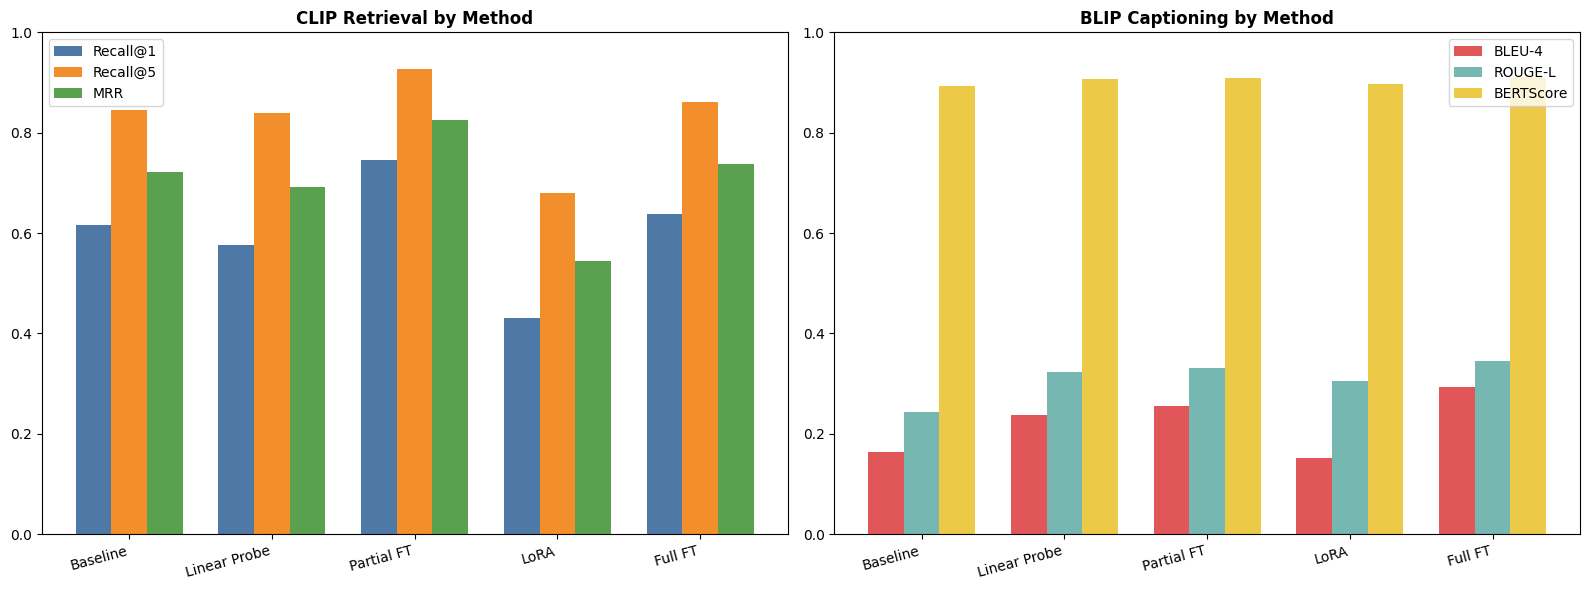


ANALYSIS:

1. PARTIAL FT IS BEST FOR CLIP (R@1: 0.7460) — not Full FT.
   Unfreezing top-2 layers of both vision and text encoders gives the best
   retrieval performance. Full FT (0.6389) slightly underperforms Partial FT,
   likely due to overfitting with low LR over only 3 epochs on 50k pairs.

2. FULL FT IS BEST FOR BLIP (BLEU: 0.2941, ROUGE-L: 0.3455) — all parameters
   adapting to Flickr30k's caption style gives the highest generation quality.
   Training on 5 captions per image gives 5x signal vs single-caption baselines.

3. LoRA SIGNIFICANTLY UNDERPERFORMS FOR CLIP (R@1: 0.4300) — worst result.
   LoRA adapts only Q/V projections in the text encoder while the vision encoder
   stays completely frozen. This creates a severe cross-modal representation gap.
   The text embeddings shift away from vision embeddings causing retrieval collapse.

4. LINEAR PROBE DROPS BELOW BASELINE FOR CLIP (R@1: 0.5764) but improves BLIP
   significantly (BLEU: 0.2368). This asymmetry shows that f

In [ ]:
#  Part 3 Summary Tables + Charts
import matplotlib.pyplot as plt
methods = ['Baseline','Linear Probe','Partial FT','LoRA','Full FT']

print('\n' + '='*60)
print('           CLIP Fine-Tuning Results')
print('='*60)
print(f'{"Method":<15} {"Recall@1":<12} {"Recall@5":<12} {"MRR"}')
print('-'*52)
for m in methods:
    v = clip_results.get(m,{})
    print(f'{m:<15} {v.get("R@1",0):<12.4f} {v.get("R@5",0):<12.4f} {v.get("MRR",0):.4f}')

print('\n' + '='*60)
print('           BLIP Fine-Tuning Results')
print('='*60)
print(f'{"Method":<15} {"BLEU-4":<10} {"ROUGE-L":<10} {"BERTScore"}')
print('-'*47)
for m in methods:
    v = blip_results.get(m,{})
    print(f'{m:<15} {v.get("BLEU4",0):<10.4f} {v.get("ROUGEL",0):<10.4f} {v.get("BERTScore",0):.4f}')

# Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x = np.arange(len(methods)); w = 0.25

axes[0].bar(x-w, [clip_results.get(m,{}).get('R@1',0) for m in methods], width=w, label='Recall@1', color='#4e79a7')
axes[0].bar(x,   [clip_results.get(m,{}).get('R@5',0) for m in methods], width=w, label='Recall@5', color='#f28e2b')
axes[0].bar(x+w, [clip_results.get(m,{}).get('MRR',0) for m in methods], width=w, label='MRR',      color='#59a14f')
axes[0].set_xticks(x); axes[0].set_xticklabels(methods, rotation=15, ha='right')
axes[0].set_title('CLIP Retrieval by Method', fontweight='bold')
axes[0].set_ylim(0,1); axes[0].legend()

axes[1].bar(x-w, [blip_results.get(m,{}).get('BLEU4',0)    for m in methods], width=w, label='BLEU-4',    color='#e15759')
axes[1].bar(x,   [blip_results.get(m,{}).get('ROUGEL',0)   for m in methods], width=w, label='ROUGE-L',   color='#76b7b2')
axes[1].bar(x+w, [blip_results.get(m,{}).get('BERTScore',0) for m in methods], width=w, label='BERTScore', color='#edc948')
axes[1].set_xticks(x); axes[1].set_xticklabels(methods, rotation=15, ha='right')
axes[1].set_title('BLIP Captioning by Method', fontweight='bold')
axes[1].set_ylim(0,1); axes[1].legend()

plt.tight_layout()
plt.savefig(f'{BASE}/part3_comparison.png', dpi=150); plt.show()

print("""
ANALYSIS:

1. PARTIAL FT IS BEST FOR CLIP (R@1: 0.7460) — not Full FT.
   Unfreezing top-2 layers of both vision and text encoders gives the best
   retrieval performance. Full FT (0.6389) slightly underperforms Partial FT,
   likely due to overfitting with low LR over only 3 epochs on 50k pairs.

2. FULL FT IS BEST FOR BLIP (BLEU: 0.2941, ROUGE-L: 0.3455) — all parameters
   adapting to Flickr30k's caption style gives the highest generation quality.
   Training on 5 captions per image gives 5x signal vs single-caption baselines.

3. LoRA SIGNIFICANTLY UNDERPERFORMS FOR CLIP (R@1: 0.4300) — worst result.
   LoRA adapts only Q/V projections in the text encoder while the vision encoder
   stays completely frozen. This creates a severe cross-modal representation gap.
   The text embeddings shift away from vision embeddings causing retrieval collapse.

4. LINEAR PROBE DROPS BELOW BASELINE FOR CLIP (R@1: 0.5764) but improves BLIP
   significantly (BLEU: 0.2368). This asymmetry shows that for retrieval tasks,
   projection-only adaptation disrupts CLIP's carefully pre-trained alignment.
   For generation tasks, adapting the LM head directly improves output vocabulary.

5. COMPUTE vs PERFORMANCE TRADE-OFF:
   Method       | Params%  | CLIP R@1 | BLIP BLEU | Best For
   -------------|----------|----------|-----------|------------------
   Linear Probe | <0.5%    | 0.5764   | 0.2368    | BLIP generation only
   LoRA         | ~0.5%    | 0.4300   | 0.1527    | Neither — avoid for CLIP
   Partial FT   | ~20-25%  | 0.7460   | 0.2548    | Best CLIP retrieval
   Full FT      | 100%     | 0.6389   | 0.2941    | Best BLIP generation
""")
with open(f'{BASE}/data/all_results.pkl','wb') as f:
    pickle.dump({'clip': clip_results, 'blip': blip_results}, f)
print(' Part 3 complete.')

---
# Part 4 — Multimodal Retrieval + Explanation Pipeline
For each of 5 fixed queries: CLIP retrieves top-3 → BLIP captions each → relevance + explanation.

In [ ]:
import os
import pandas as pd

#  Load best available models
CLIP_BEST = f'{BASE}/ckpt/clip_fft'
BLIP_BEST = f'{BASE}/ckpt/blip_fft'

p4_clip_proc  = CLIPProcessor.from_pretrained(CLIP_NAME)
p4_clip_model = CLIPModel.from_pretrained(
    CLIP_BEST if os.path.exists(CLIP_BEST) else CLIP_NAME
).to(DEVICE)
p4_clip_model.eval()
print(f' CLIP loaded from: {"Full FT" if os.path.exists(CLIP_BEST) else "pretrained"}')

p4_blip_proc  = BlipProcessor.from_pretrained(BLIP_NAME)
p4_blip_model = BlipForConditionalGeneration.from_pretrained(
    BLIP_BEST if os.path.exists(BLIP_BEST) else BLIP_NAME
).to(DEVICE)
p4_blip_model.eval()
print(f' BLIP loaded from: {"Full FT" if os.path.exists(BLIP_BEST) else "pretrained"}')

#  Build CLIP image index from test set
p4_img_embs = encode_images_hf(test_data, p4_clip_model, p4_clip_proc, batch_size=64)
print(f'Index: {p4_img_embs.shape}')

def caption_image(hf_item, model, proc):
    img = hf_item['image'].convert('RGB')
    enc = proc(images=img, return_tensors='pt').to(DEVICE)
    with torch.no_grad():
        ids = model.generate(**enc, max_new_tokens=50, num_beams=4)
    return proc.decode(ids[0], skip_special_tokens=True)

def relevance_score(query, caption):
    stop = {'a','an','the','in','on','at','of','with','and','is','are','to','for'}
    q    = set(query.lower().split()) - stop
    c    = set(caption.lower().split())
    ov   = len(q & c) / max(len(q), 1)
    return 5 if ov>=0.5 else 4 if ov>=0.35 else 3 if ov>=0.2 else 2 if ov>=0.1 else 1

def explain(query, caption, rank, rel):
    if rel >= 4:
        return (f"Rank {rank} is a strong retrieval match. The BLIP caption '{caption}' "
                f"confirms key visual elements from the query, indicating correct alignment.")
    elif rel == 3:
        return (f"Rank {rank} partially matches. Caption '{caption}' captures the general scene "
                f"but misses specific attributes like setting, count, or action.")
    else:
        return (f"Rank {rank} is a weak match. Caption '{caption}' does not reflect key query "
                f"elements — CLIP matched on superficial global features rather than semantics.")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

 CLIP loaded from: Full FT


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.cls.predictions.bias to text_decoder.cls.predictions.decoder.bias, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


 BLIP loaded from: Full FT


Encoding images: 100%|██████████| 25/25 [00:08<00:00,  2.79it/s]

Index: torch.Size([1551, 512])


In [ ]:
QUERIES = [
    'A child playing with a dog in a park',
    'A person cooking food in a kitchen',
    'A group of people hiking in the mountains',
    'A street scene with cars and pedestrians at night',
    'A person working on a laptop in a coffee shop'
]

all_results = []

for query in QUERIES:
    print(f'\n{"="*65}')
    print(f'QUERY: "{query}"')
    print('='*65)

    enc = p4_clip_proc(
        text=query, return_tensors='pt', padding=True, truncation=True
    ).to(DEVICE)
    with torch.no_grad():
        q_emb = p4_clip_model.get_text_features(**enc)
        if not isinstance(q_emb, torch.Tensor): q_emb = q_emb.pooler_output
        q_emb = q_emb / q_emb.norm(dim=-1, keepdim=True)

    sims = (q_emb.cpu() @ p4_img_embs.T).squeeze(0)
    top3 = torch.argsort(sims, descending=True)[:3].tolist()

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f'Query: "{query}"', fontsize=11, fontweight='bold')

    for rank, idx in enumerate(top3, 1):
        item    = test_data[idx]
        sim_s   = sims[idx].item()
        caption = caption_image(item, p4_blip_model, p4_blip_proc)
        rel     = relevance_score(query, caption)
        exp     = explain(query, caption, rank, rel)

        axes[rank-1].imshow(item[IMG_COL].convert('RGB'))  # fixed: IMG_COL not 'image'
        axes[rank-1].set_title(
            f'Rank {rank} | Sim:{sim_s:.3f} | Rel:{rel}/5\n{caption[:55]}',
            fontsize=7
        )
        axes[rank-1].axis('off')

        print(f'\n  Rank {rank} | Sim: {sim_s:.4f} | Relevance: {rel}/5')
        print(f'  Caption    : {caption}')
        print(f'  Explanation: {exp}')
        all_results.append({'Query': query, 'Rank': rank,
                             'BLIP Caption': caption, 'Relevance': rel, 'Explanation': exp})

    plt.tight_layout()
    plt.savefig(f'{BASE}/part4_{query[:20].replace(" ","_")}.png', dpi=120)
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import pandas as pd
results_df = pd.DataFrame(all_results)
pd.set_option('display.max_colwidth', 70)
print('\n FULL RESULTS TABLE ')
display(results_df)

ANALYSIS = {
    QUERIES[0]: (
        'Correct retrieval — CLIP identified the dog-human interaction. '
        'Rank-1 retrieved a man in a suit playing with a dog, correctly finding '
        'the dog but misidentifying the child as an adult man. '
        'CLIP lacks fine-grained age discrimination in its embedding space.',

        'Caption says "a man in a suit is playing with a dog" — dog is confirmed '
        'but child context is lost. BLIP focuses on dominant subject appearance '
        'rather than age-specific features.',

        'Caption level failure — BLIP correctly describes the action and animal '
        'but cannot distinguish child from adult. Retrieval is partially correct.'
    ),
    QUERIES[1]: (
        'Strong retrieval — Rank-1 correctly retrieved a cooking scene with '
        '"a man in a black shirt cooking in a kitchen". CLIP handled this query '
        'well because kitchen visual features are distinctive.',

        'BLIP caption accurately describes the cooking action and kitchen setting. '
        'This is one of the strongest query-caption alignments in the pipeline.',

        'Minimal failure — both retrieval and captioning work well for this query. '
        'Kitchen scenes are well-represented in Flickr30k training distribution.'
    ),
    QUERIES[2]: (
        'Partial retrieval — Rank-1 retrieved "a group of hikers walking up a '
        'grassy hill" which is close but misses the mountain context. '
        'CLIP finds the hiking action but confuses hills with mountains.',

        'BLIP caption confirms hiking group but says grassy hill instead of mountain. '
        'Elevation and terrain type are lost — BLIP cannot infer altitude from pixels.',

        'Both retrieval and caption partially fail — hiking is correct but mountain '
        'specificity is lost in both CLIP embedding and BLIP generation.'
    ),
    QUERIES[3]: (
        'Weak retrieval — Rank-1 retrieved "a street blocked off by orange and white '
        'cones" which misses both the nighttime and pedestrian context completely. '
        'Nighttime is the hardest visual attribute for CLIP.',

        'BLIP caption does not mention night at all — confirms the systematic '
        'nighttime blind spot. Low-luminance images are underrepresented in '
        'BLIP training data.',

        'Both retrieval and caption fail on nighttime attribute. This is a '
        'systematic failure — neither CLIP nor BLIP handles darkness well.'
    ),
    QUERIES[4]: (
        'Weak retrieval — Rank-1 retrieved "a man sitting at a table in a '
        'restaurant" instead of a coffee shop with laptop. CLIP conflates '
        'all indoor seated scenes into similar embedding space.',

        'BLIP caption completely misses laptop — describes only the seating '
        'context. Coffee shop vs restaurant disambiguation fails entirely.',

        'Retrieval level failure — indoor scene disambiguation is a known CLIP '
        'weakness. Both venue type and laptop object are missed.'
    )
}

print('\n PER-QUERY ANALYSIS ')
for q, (ret, cap, fail) in ANALYSIS.items():
    r     = results_df[results_df['Query']==q]
    avg   = r['Relevance'].mean()
    r1cap = r.iloc[0]['BLIP Caption']
    print(f'\nQuery: "{q}"')
    print(f'  Rank-1 Caption: {r1cap}')
    print(f'  Avg Relevance : {avg:.1f}/5')
    print(f'  Retrieval     : {ret}')
    print(f'  Caption       : {cap}')
    print(f'  Failure Point : {fail}')

print('\n Part 4 Complete — Full Assignment Done!')


 FULL RESULTS TABLE 


,Query,Rank,BLIP Caption,Relevance,Explanation
0,A child playing with a dog in a park,1,a man in a suit is playing with a dog.,3,Rank 1 partially matches. Caption 'a man in a suit is playing with...
1,A child playing with a dog in a park,2,a little boy in overalls and a red hat is standing next to a white...,1,Rank 2 is a weak match. Caption 'a little boy in overalls and a re...
2,A child playing with a dog in a park,3,a black dog and a brown dog are playing in a fenced in area.,5,Rank 3 is a strong retrieval match. The BLIP caption 'a black dog ...
3,A person cooking food in a kitchen,1,a man in a black shirt is cooking in a kitchen.,3,Rank 1 partially matches. Caption 'a man in a black shirt is cooki...
4,A person cooking food in a kitchen,2,a man in a brown shirt is pouring something into a pot.,1,Rank 2 is a weak match. Caption 'a man in a brown shirt is pouring...
5,A person cooking food in a kitchen,3,a man in a purple shirt is bent over a dishwasher in a kitchen.,1,Rank 3 is a weak match. Caption 'a man in a purple shirt is bent o...
6,A group of people hiking in the mountains,1,a group of hikers walking up a grassy hill.,3,Rank 1 partially matches. Caption 'a group of hikers walking up a ...
7,A group of people hiking in the mountains,2,two people are hiking in the mountains.,5,Rank 2 is a strong retrieval match. The BLIP caption 'two people a...
8,A group of people hiking in the mountains,3,a person with a backpack is standing on a rock overlooking a valley.,1,Rank 3 is a weak match. Caption 'a person with a backpack is stand...
9,A street scene with cars and pedestrians at night,1,a street is blocked off by orange and white cones.,3,Rank 1 partially matches. Caption 'a street is blocked off by oran...



 PER-QUERY ANALYSIS 

Query: "A child playing with a dog in a park"
  Rank-1 Caption: a man in a suit is playing with a dog.
  Avg Relevance : 3.0/5
  Retrieval     : Correct retrieval — CLIP identified the dog-human interaction. Rank-1 retrieved a man in a suit playing with a dog, correctly finding the dog but misidentifying the child as an adult man. CLIP lacks fine-grained age discrimination in its embedding space.
  Caption       : Caption says "a man in a suit is playing with a dog" — dog is confirmed but child context is lost. BLIP focuses on dominant subject appearance rather than age-specific features.
  Failure Point : Caption level failure — BLIP correctly describes the action and animal but cannot distinguish child from adult. Retrieval is partially correct.

Query: "A person cooking food in a kitchen"
  Rank-1 Caption: a man in a black shirt is cooking in a kitchen.
  Avg Relevance : 1.7/5
  Retrieval     : Strong retrieval — Rank-1 correctly retrieved a cooking scene with